In [2]:
# Import TensorFlow library
import tensorflow as tf

# Import NumPy library
import numpy as np

# Import Matplotlib library
import matplotlib.pyplot as plt

# Import required CNN layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Set the dataset path

dataset_path = "../data/raw/NEU-DET"

# Set image folder paths

train_images = dataset_path + "/train/Images"
val_images = dataset_path + "/validation/Images"

# Set image size

image_size = 224

# Define defect classes

classes = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

print("Dataset paths and classes are ready!")

Dataset paths and classes are ready!


In [4]:
import os
from PIL import Image

In [5]:
# Create empty lists

X_train = []
y_train = []

# Load training images

for class_name in classes:

    class_path = os.path.join(train_images, class_name)

    for image_name in os.listdir(class_path):

        image_path = os.path.join(class_path, image_name)

        # Open image
        img = Image.open(image_path)

        # Convert image into RGB
        img = img.convert("RGB")

        # Resize image
        img = img.resize((image_size, image_size))

        # Convert image into NumPy array
        img_array = np.array(img)

        # Store image and label
        X_train.append(img_array)
        y_train.append(classes.index(class_name))

print("Training images loaded successfully!")
print("Total training images:", len(X_train))
print("Total labels:", len(y_train))

Training images loaded successfully!
Total training images: 1440
Total labels: 1440


In [6]:
# Create empty lists for validation data

X_val = []
y_val = []

# Load validation images

for class_name in classes:

    class_path = os.path.join(val_images, class_name)

    for image_name in os.listdir(class_path):

        image_path = os.path.join(class_path, image_name)

        # Open image
        img = Image.open(image_path)

        # Convert image into RGB
        img = img.convert("RGB")

        # Resize image
        img = img.resize((image_size, image_size))

        # Convert image into NumPy array
        img_array = np.array(img)

        # Store image and label
        X_val.append(img_array)
        y_val.append(classes.index(class_name))

print("Validation images loaded successfully!")
print("Total validation images:", len(X_val))
print("Total validation labels:", len(y_val))

Validation images loaded successfully!
Total validation images: 360
Total validation labels: 360


In [7]:
# Convert training data into NumPy arrays

X_train = np.array(X_train)
y_train = np.array(y_train)

# Convert validation data into NumPy arrays

X_val = np.array(X_val)
y_val = np.array(y_val)

# Display dataset shapes

print("Training Images Shape:", X_train.shape)
print("Training Labels Shape:", y_train.shape)

print("Validation Images Shape:", X_val.shape)
print("Validation Labels Shape:", y_val.shape)

Training Images Shape: (1440, 224, 224, 3)
Training Labels Shape: (1440,)
Validation Images Shape: (360, 224, 224, 3)
Validation Labels Shape: (360,)


In [8]:
# Normalize training images

X_train = X_train / 255.0

# Normalize validation images

X_val = X_val / 255.0

print("Image normalization completed!")

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Image normalization completed!
Minimum pixel value: 0.0
Maximum pixel value: 1.0


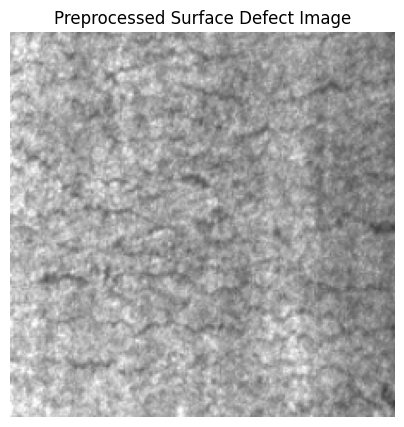

Label: 0
Defect Class: crazing


In [9]:
# Display one training image

plt.figure(figsize=(5, 5))

plt.imshow(X_train[0])

plt.title("Preprocessed Surface Defect Image")

plt.axis("off")

plt.show()

# Display image label

print("Label:", y_train[0])
print("Defect Class:", classes[y_train[0]])

In [10]:
# Create CNN model

model = Sequential()

# First Convolution Layer
model.add(Conv2D(32, (3, 3), activation='relu',
                 input_shape=(224, 224, 3)))

# First Pooling Layer
model.add(MaxPooling2D(pool_size=(2, 2)))

# Second Convolution Layer
model.add(Conv2D(64, (3, 3), activation='relu'))

# Second Pooling Layer
model.add(MaxPooling2D(pool_size=(2, 2)))

# Third Convolution Layer
model.add(Conv2D(128, (3, 3), activation='relu'))

# Third Pooling Layer
model.add(MaxPooling2D(pool_size=(2, 2)))

# Convert feature maps into one-dimensional data
model.add(Flatten())

# Fully Connected Layer
model.add(Dense(128, activation='relu'))

# Dropout Layer
model.add(Dropout(0.5))

# Output Layer - 6 defect classes
model.add(Dense(6, activation='softmax'))

print("CNN model created successfully!")

C:\Users\salun\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN model created successfully!


In [11]:
# Display CNN model architecture

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,169,734 (42.61 MB)

 Trainable params: 11,169,734 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Compile the CNN model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [13]:
# Train the CNN model

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 38s 786ms/step - accuracy: 0.2313 - loss: 1.9066 - val_accuracy: 0.2778 - val_loss: 1.8869
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 34s 747ms/step - accuracy: 0.4278 - loss: 1.3605 - val_accuracy: 0.6361 - val_loss: 1.1929
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 33s 741ms/step - accuracy: 0.5271 - loss: 1.2202 - val_accuracy: 0.4306 - val_loss: 1.1815
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 33s 741ms/step - accuracy: 0.7201 - loss: 0.7869 - val_accuracy: 0.7278 - val_loss: 0.7152
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 33s 742ms/step - accuracy: 0.8188 - loss: 0.5470 - val_accuracy: 0.8333 - val_loss: 0.4452
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 33s 741ms/step - accuracy: 0.8639 - loss: 0.4262 - val_accuracy: 0.8194 - val_loss: 0.4651
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 33s 735ms/step - accuracy: 0.8042 - loss: 0.5511 - val_accuracy: 0.5500 - val_loss: 1.0351
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 34s 749ms/step - accuracy: 0.8639 - loss: 0.4047 - val_accu

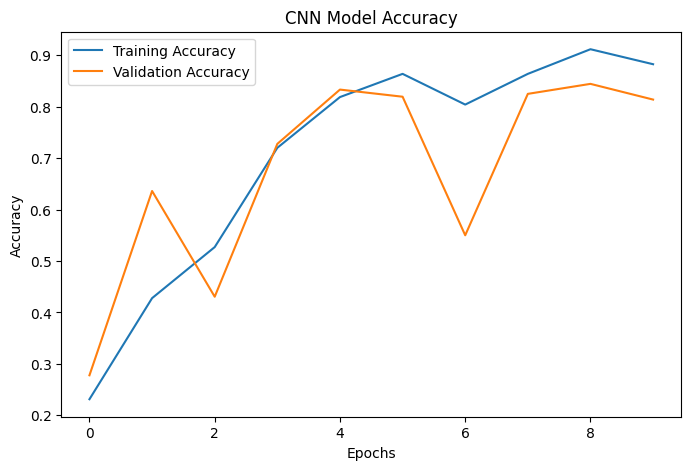

In [14]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

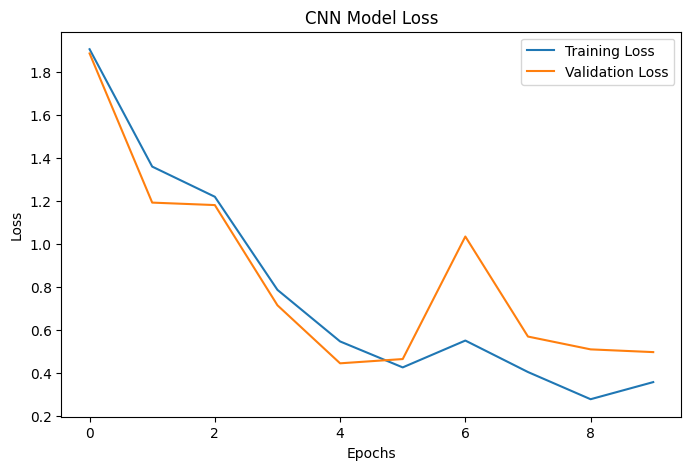

In [15]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("CNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.show()

In [16]:
# Evaluate the CNN model

val_loss, val_accuracy = model.evaluate(X_val, y_val)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy * 100, "%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 212ms/step - accuracy: 0.8139 - loss: 0.4973
Validation Loss: 0.49734801054000854
Validation Accuracy: 81.38889074325562 %


In [17]:
from sklearn.metrics import classification_report, confusion_matrix

In [18]:
# Predict classes for validation images

y_pred = model.predict(X_val)

# Convert predicted probabilities into class labels

y_pred = np.argmax(y_pred, axis=1)

print("Predictions completed successfully!")
print("Total predictions:", len(y_pred))

12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 218ms/step
Predictions completed successfully!
Total predictions: 360


In [19]:
print(classification_report(y_val, y_pred, target_names=classes))

                 precision    recall  f1-score   support

        crazing       0.91      0.97      0.94        60
      inclusion       0.79      0.63      0.70        60
        patches       0.97      0.93      0.95        60
 pitted_surface       0.70      0.87      0.78        60
rolled-in_scale       0.74      1.00      0.85        60
      scratches       0.83      0.48      0.61        60

       accuracy                           0.81       360
      macro avg       0.82      0.81      0.80       360
   weighted avg       0.82      0.81      0.80       360



In [20]:
cm = confusion_matrix(y_val, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[58  0  2  0  0  0]
 [ 0 38  0 20  1  1]
 [ 4  0 56  0  0  0]
 [ 1  2  0 52  0  5]
 [ 0  0  0  0 60  0]
 [ 1  8  0  2 20 29]]


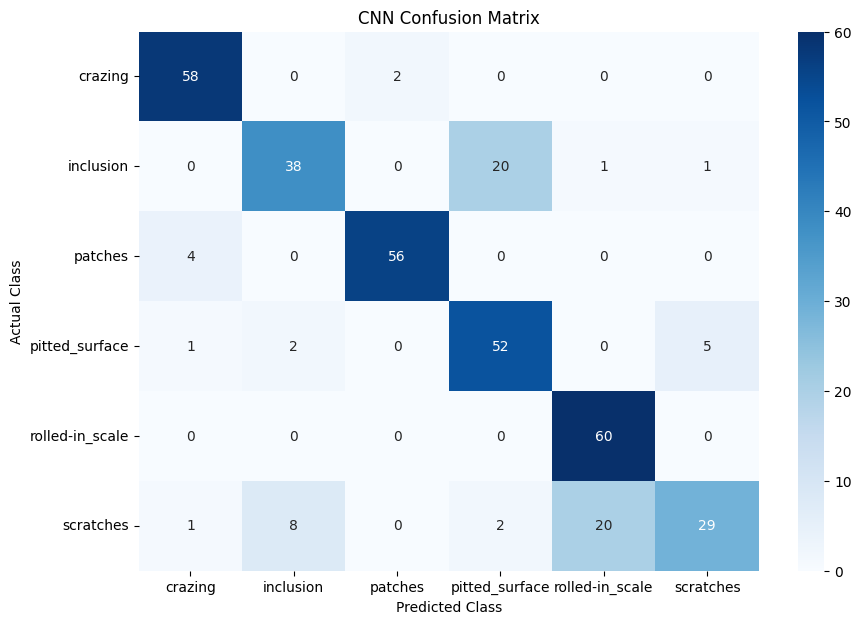

In [21]:
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [22]:
model.save("../models/baseline_cnn.keras")

print("CNN Model saved successfully!")

CNN Model saved successfully!
